# DRY BEAN CLASSIFIER

_LIBRERIE_

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    StandardScaler,
    label_binarize,
    LabelEncoder
)
from sklearn.decomposition import PCA

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

_CARICAMENTO DEL DATASET E PRIMA ESPLORAZIONE_

In [2]:
df = pd.read_excel("Dry_Bean_Dataset.xlsx")

df.info()

print("\nDimensione:", df.shape)

print("\nPrime 5 osservazioni:")
print(df.head())

print("\nStatistiche descrittive:")
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

_DATA CLEANING_

In [3]:
#Controllo di eventuali valori mancanti
print("Valori mancanti:")
print(df.isnull().sum())

#Controllo di eventuali valori duplicati
print("\nDuplicati:")
print(df.duplicated().sum())

#Rimozione dei duplicati
df = df.drop_duplicates().reset_index(drop=True)

print("\nNuova dimensione del dataset:")
print(df.shape)

Valori mancanti:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Duplicati:
68

Nuova dimensione del dataset:
(13543, 17)


_EXPLORATORY DATA ANALYSIS_

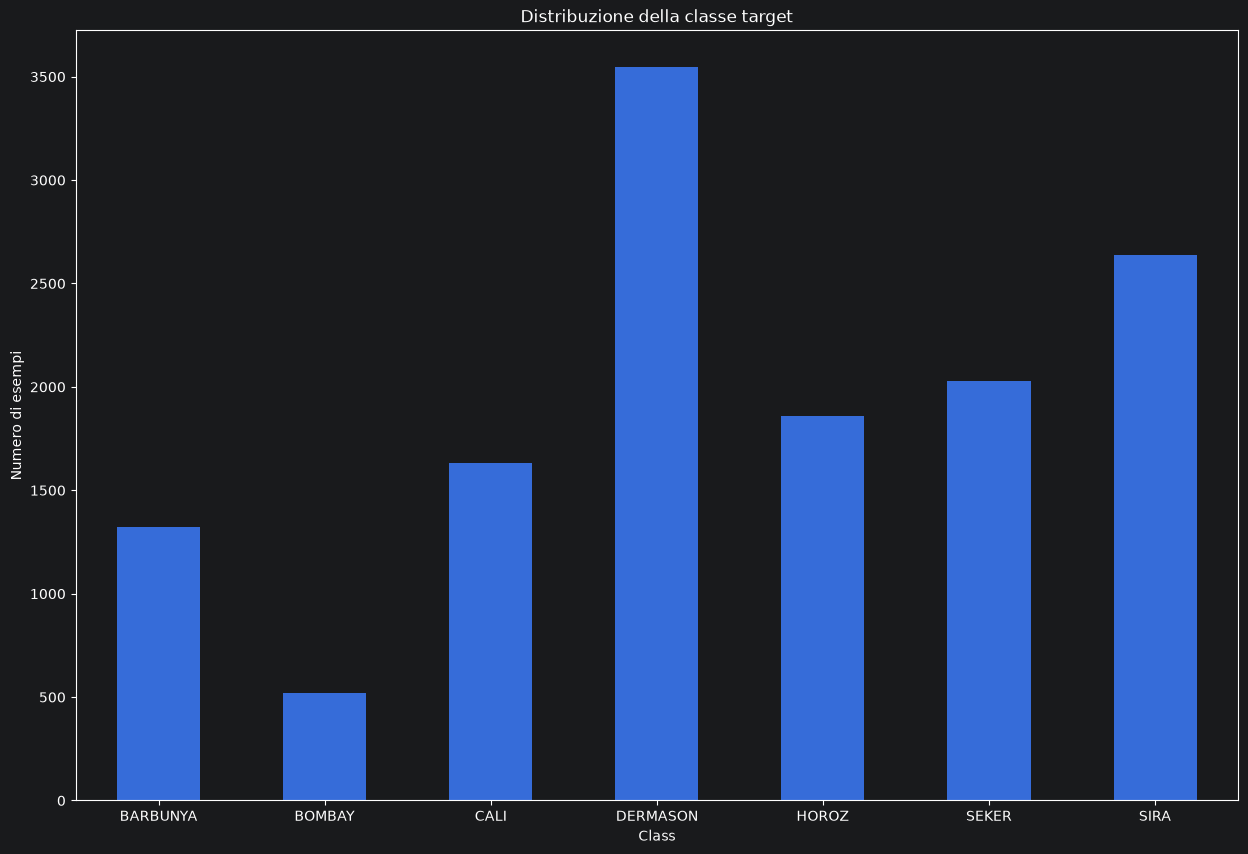

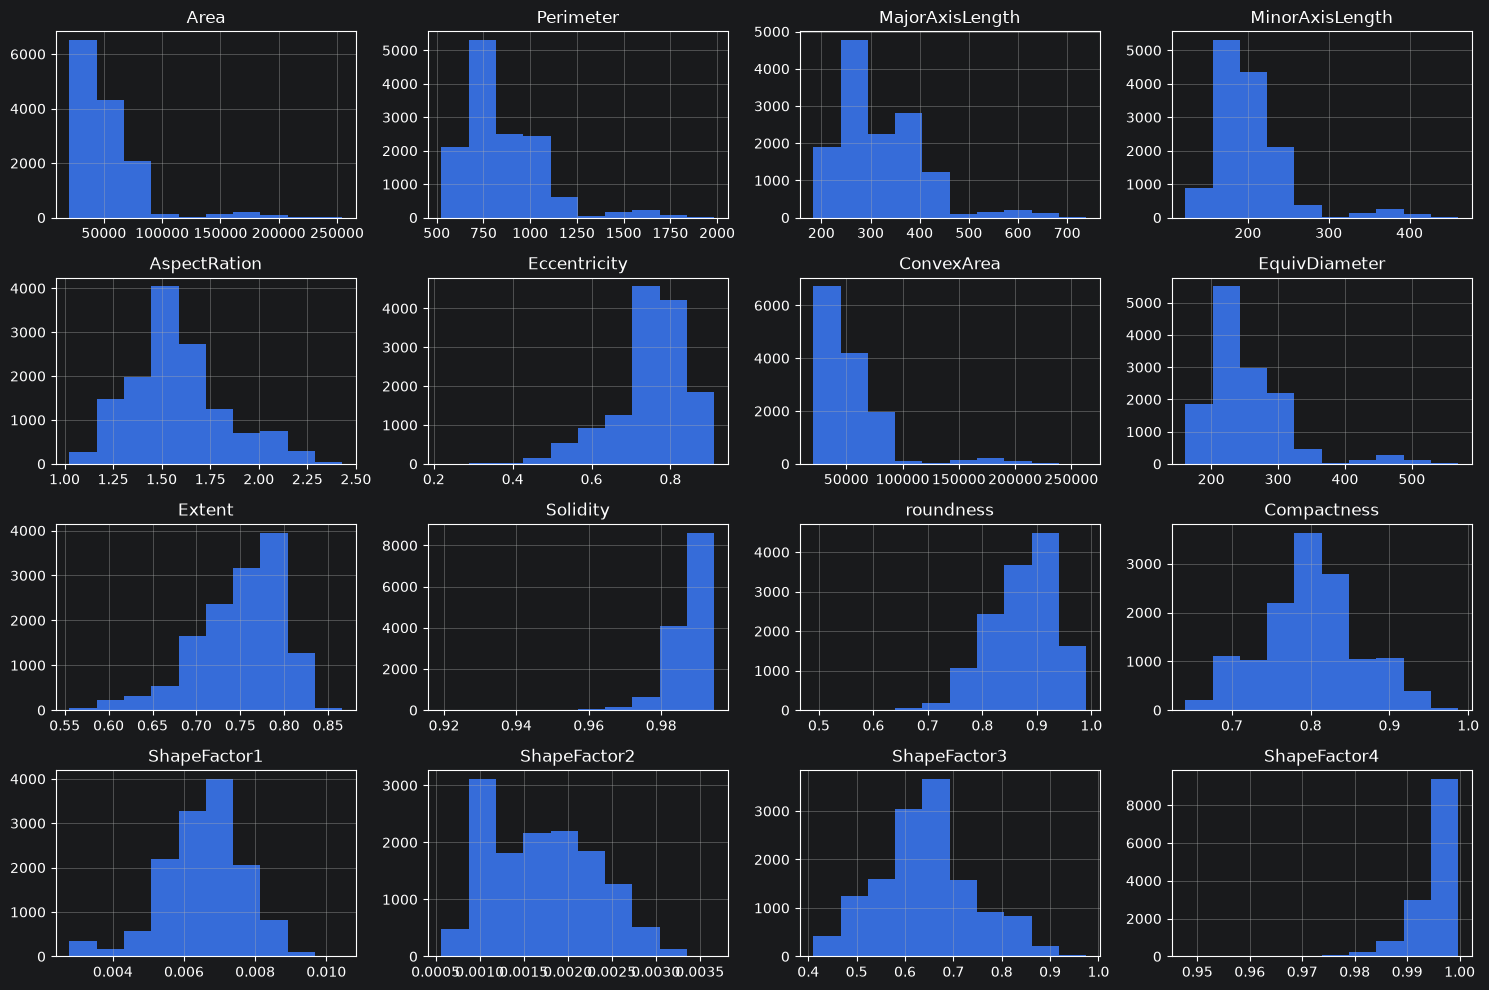

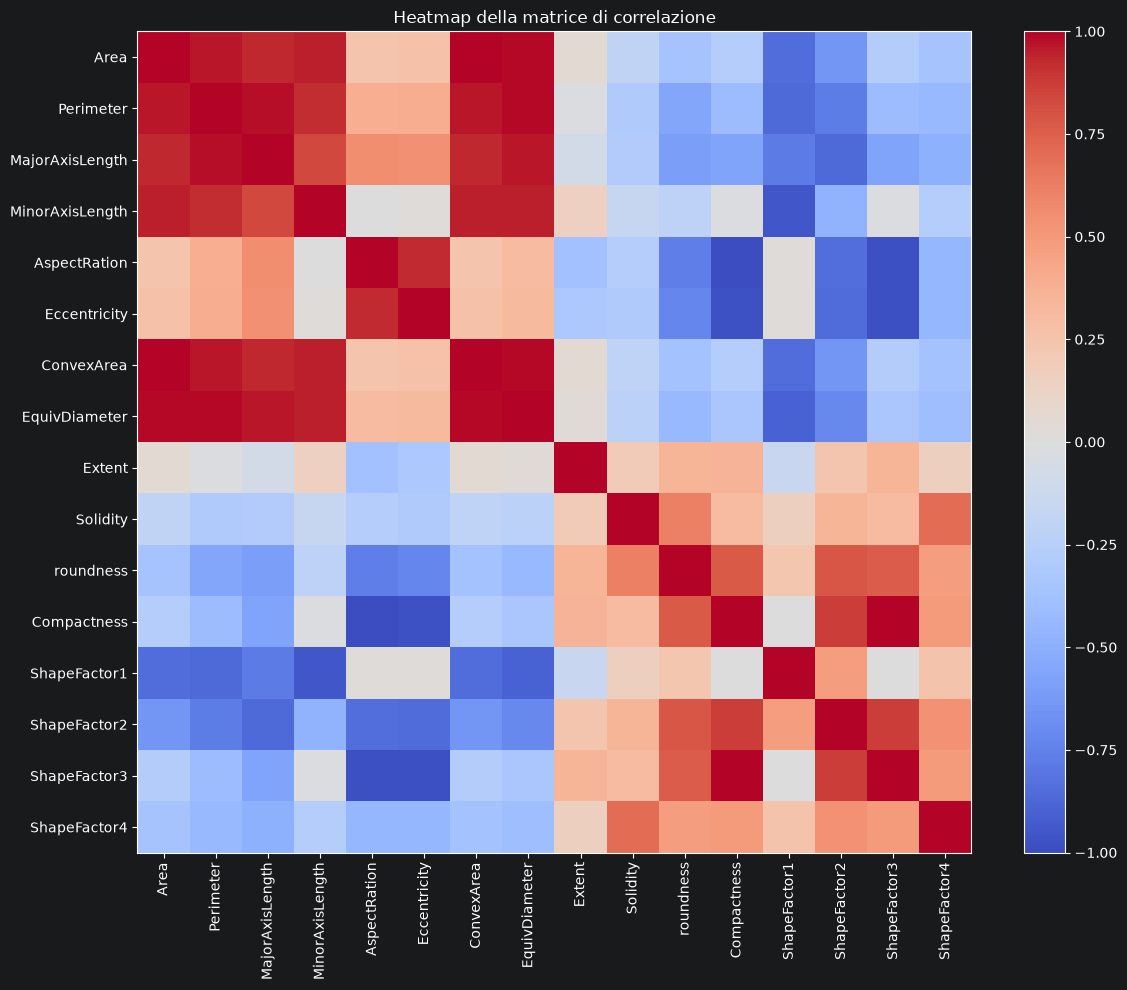

In [4]:
#1. Distribuzione classe target
df["Class"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(15, 10)
)

plt.xlabel("Class")
plt.ylabel("Numero di esempi")
plt.title("Distribuzione della classe target")
plt.xticks(rotation=0)
plt.show()


#2. Distribuzione delle feature
df.drop(columns="Class").hist(
    figsize=(15, 10)
)

plt.tight_layout()
plt.show()

#3. Matrice di correlazione
corr = df.drop(columns="Class").corr()

plt.figure(figsize=(12, 10))

plt.imshow(
    corr,
    cmap="coolwarm",
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar()
plt.title("Heatmap della matrice di correlazione")

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=90
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.tight_layout()
plt.show()

_PREPROCESSING_

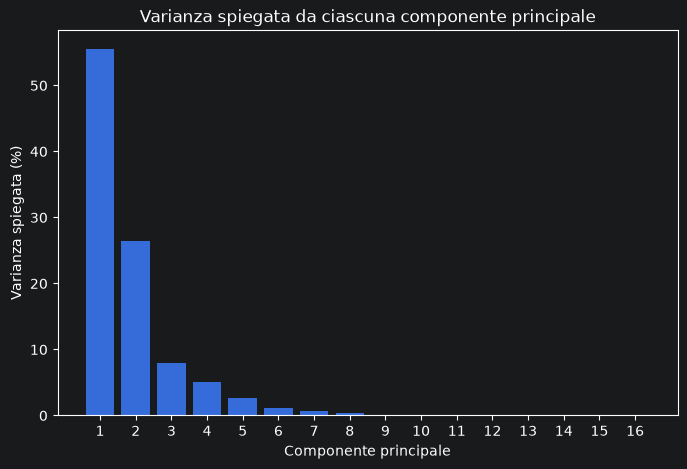

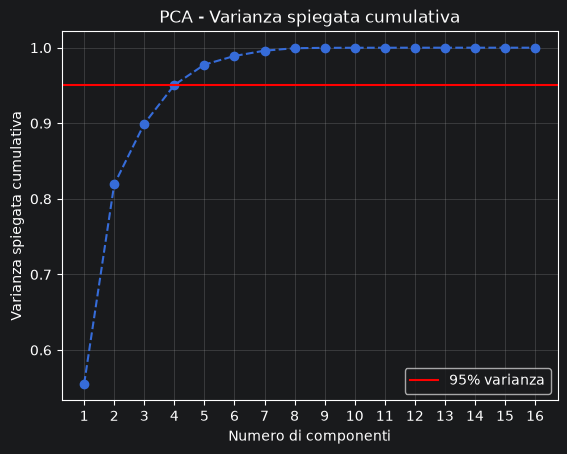

Numero di componenti necessarie per mantenere almeno il 95% della varianza: 4
Varianza spiegata totale: 0.9506804505724835


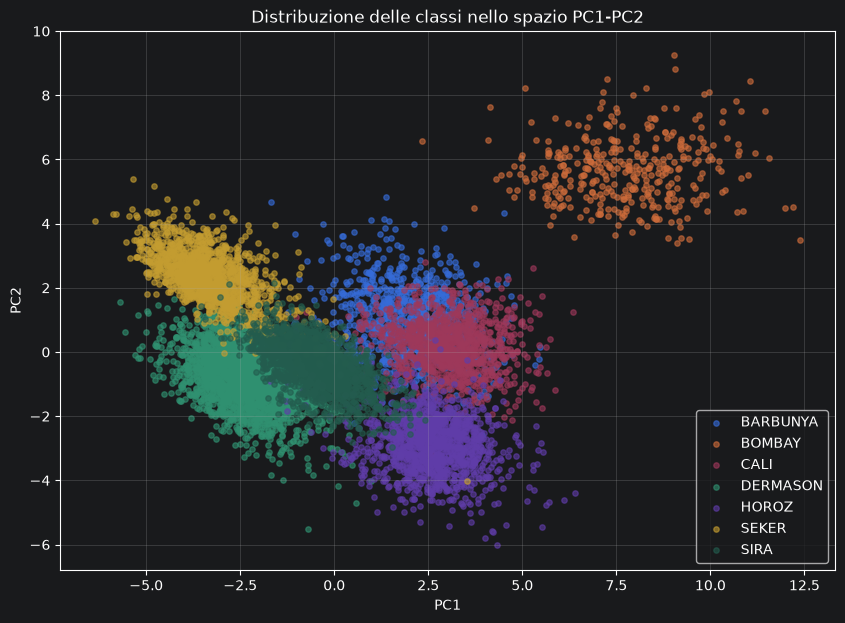

In [5]:
#1. Split stratificato in Train e Test
X = df.drop(columns="Class")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

#2. Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#3. PCA
pca_full = PCA()

pca_full.fit(X_train_scaled)

#Bar plot della varianza spiegata individuale
varianza_spiegata = pca_full.explained_variance_ratio_ * 100

componenti = np.arange(1, len(varianza_spiegata) + 1)

plt.figure(figsize=(8, 5))

plt.bar(
    componenti,
    varianza_spiegata
)

plt.xlabel("Componente principale")
plt.ylabel("Varianza spiegata (%)")
plt.title("Varianza spiegata da ciascuna componente principale")

plt.xticks(componenti)

plt.show()

# Scree plot per la selezione delle componenti
varianza_cumulativa = np.cumsum(pca_full.explained_variance_ratio_)

componenti = np.arange(1, len(varianza_cumulativa) + 1)

plt.plot(
    componenti,
    varianza_cumulativa,
    marker="o",
    linestyle="--"
)

plt.axhline(
    y=0.95,
    color="red",
    linestyle="-",
    label="95% varianza"
)

plt.xlabel("Numero di componenti")
plt.ylabel("Varianza spiegata cumulativa")
plt.title("PCA - Varianza spiegata cumulativa")

plt.xticks(componenti)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

#Numero di componenti necessarie per mantenere almeno il 95% della varianza
n_componenti_95 = np.argmax(varianza_cumulativa >= 0.95) + 1

print(
    "Numero di componenti necessarie per mantenere almeno il 95% della varianza:",
    n_componenti_95
)

print("Varianza spiegata totale:", varianza_cumulativa[n_componenti_95 - 1])

# Applicazione della PCA: fit sul training set e trasformazione del test set
pca = PCA(n_components=4)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

#Scatter plot delle classi sulle prime due componenti principali
plt.figure(figsize=(10, 7))

for classe in sorted(y_train.unique()):
    mask = y_train == classe

    plt.scatter(
        X_train_pca[mask, 0],
        X_train_pca[mask, 1],
        label=classe,
        alpha=0.6,
        s=15
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Distribuzione delle classi nello spazio PC1-PC2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [6]:
#1. Logistic Regression
log_reg = LogisticRegression(
    max_iter=3000,
    random_state=42
)

log_reg.fit(X_train_pca, y_train)

y_pred_lr = log_reg.predict(X_test_pca)

print("REPORT DI CLASSIFICAZIONE LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_lr, zero_division=0))

#2. Support Vector Machine
svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)

svm.fit(X_train_pca, y_train)

y_pred_svm = svm.predict(X_test_pca)

print("REPORT DI CLASSIFICAZIONE SVM")
print(classification_report(y_test, y_pred_svm, zero_division=0))

#3. K-Nearest Neighbors
knn = KNeighborsClassifier(
    n_neighbors=5
)

knn.fit(X_train_pca, y_train)

y_pred_knn = knn.predict(X_test_pca)

print("REPORT DI CLASSIFICAZIONE KNN")
print(classification_report(y_test, y_pred_knn, zero_division=0))

REPORT DI CLASSIFICAZIONE LOGISTIC REGRESSION
              precision    recall  f1-score   support

    BARBUNYA       0.81      0.71      0.76       397
      BOMBAY       1.00      0.99      1.00       156
        CALI       0.81      0.87      0.83       489
    DERMASON       0.92      0.90      0.91      1064
       HOROZ       0.95      0.94      0.95       558
       SEKER       0.93      0.94      0.93       608
        SIRA       0.84      0.87      0.86       791

    accuracy                           0.89      4063
   macro avg       0.89      0.89      0.89      4063
weighted avg       0.89      0.89      0.89      4063

REPORT DI CLASSIFICAZIONE SVM
              precision    recall  f1-score   support

    BARBUNYA       0.85      0.70      0.77       397
      BOMBAY       1.00      1.00      1.00       156
        CALI       0.80      0.89      0.84       489
    DERMASON       0.92      0.91      0.91      1064
       HOROZ       0.95      0.94      0.95       558
  

_CONFUSION MATRIX_

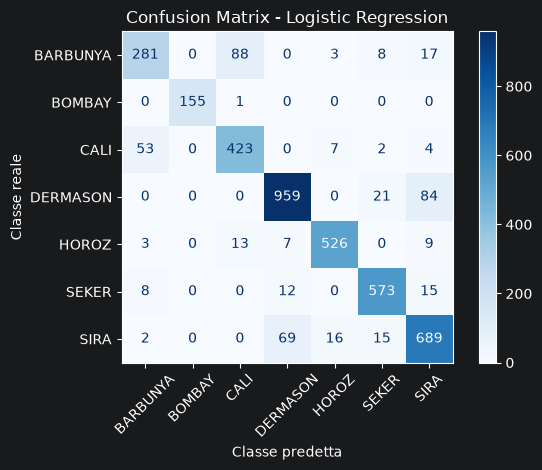

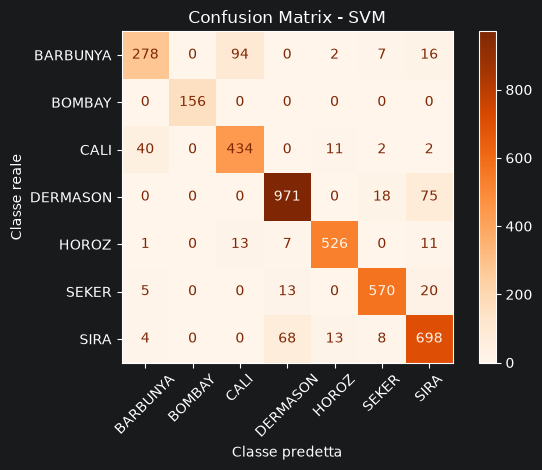

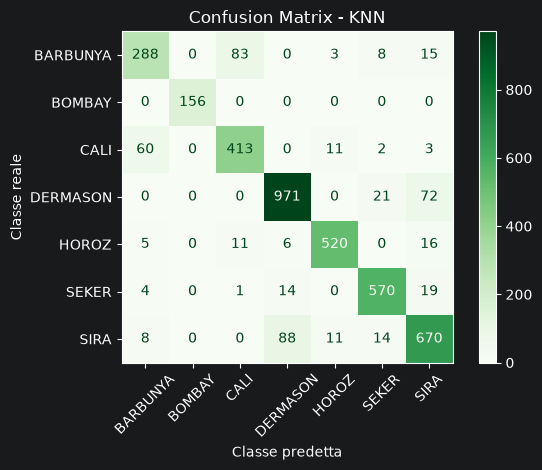

In [7]:
modelli_pred = {
    "Logistic Regression": (y_pred_lr, "Blues"),
    "SVM": (y_pred_svm, "Oranges"),
    "KNN": (y_pred_knn, "Greens")
}

classi = sorted(y.unique())

for nome, (y_pred, colore) in modelli_pred.items():

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=classi,
        cmap=colore,
        values_format="d"
    )

    plt.title(f"Confusion Matrix - {nome}")
    plt.xlabel("Classe predetta")
    plt.ylabel("Classe reale")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

_ROC CURVE_

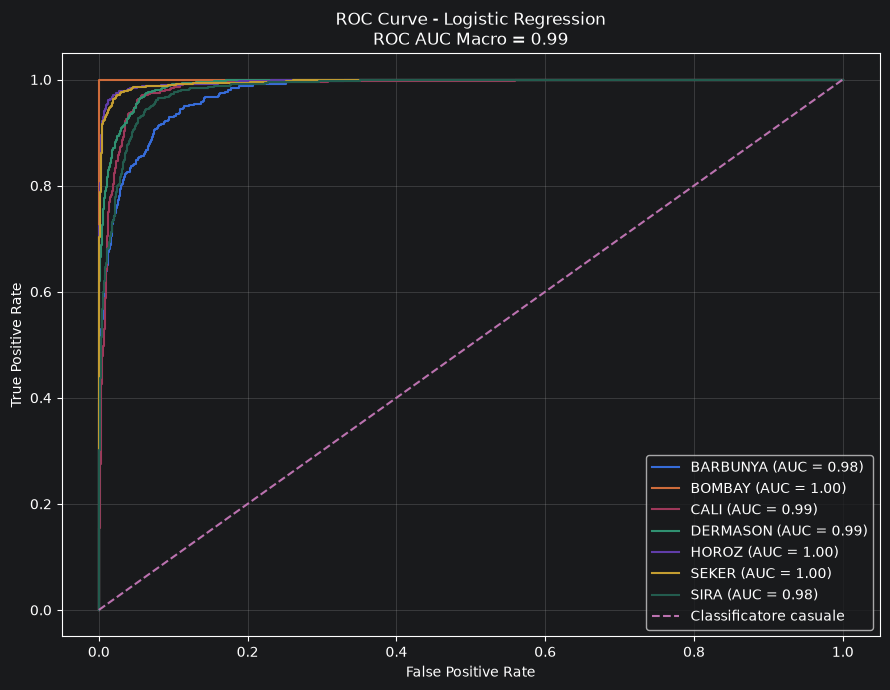

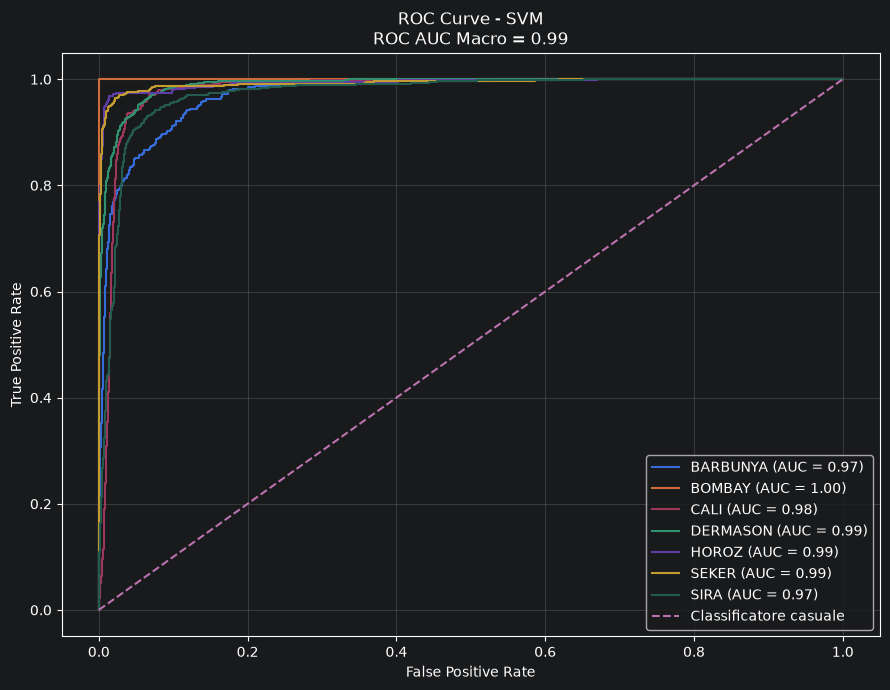

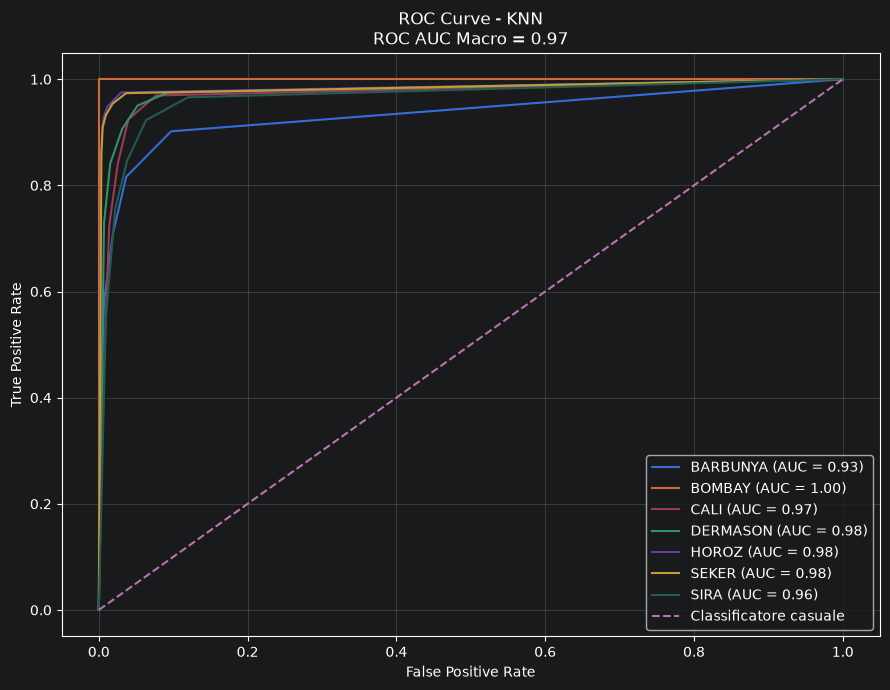

In [8]:
#1. Binarizzazione del target per strategia One-vs-Rest
classi = sorted(y.unique())

y_test_bin = label_binarize(
    y_test,
    classes=classi
)

#2. Score dei tre classificatori
y_score_lr = log_reg.predict_proba(X_test_pca)

y_score_svm = svm.decision_function(X_test_pca)

y_score_knn = knn.predict_proba(X_test_pca)


#3. Dizionario dei modelli
modelli_score = {
    "Logistic Regression": y_score_lr,
    "SVM": y_score_svm,
    "KNN": y_score_knn
}


#4. ROC Curve per ogni classificatore
for nome, y_score in modelli_score.items():

    plt.figure(figsize=(9, 7))

    auc_classi = []

    for i, classe in enumerate(classi):

        fpr, tpr, _ = roc_curve(
            y_test_bin[:, i],
            y_score[:, i]
        )

        roc_auc = auc(fpr, tpr)
        auc_classi.append(roc_auc)

        plt.plot(
            fpr,
            tpr,
            label=f"{classe} (AUC = {roc_auc:.2f})"
        )


    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Classificatore casuale"
    )

    auc_macro = np.mean(auc_classi)

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(
        f"ROC Curve - {nome}\n"
        f"ROC AUC Macro = {auc_macro:.2f}"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

_CONFRONTO TRA I MODELLI_

                     Accuracy  Precision Macro  Recall Macro  F1-score Macro  \
Logistic Regression  0.887522         0.893192      0.889126        0.890460   
SVM                  0.894167         0.901554      0.894707        0.896770   
KNN                  0.883091         0.889381      0.885578        0.887215   

                     ROC AUC Macro  
Logistic Regression       0.989829  
SVM                       0.986085  
KNN                       0.973741  


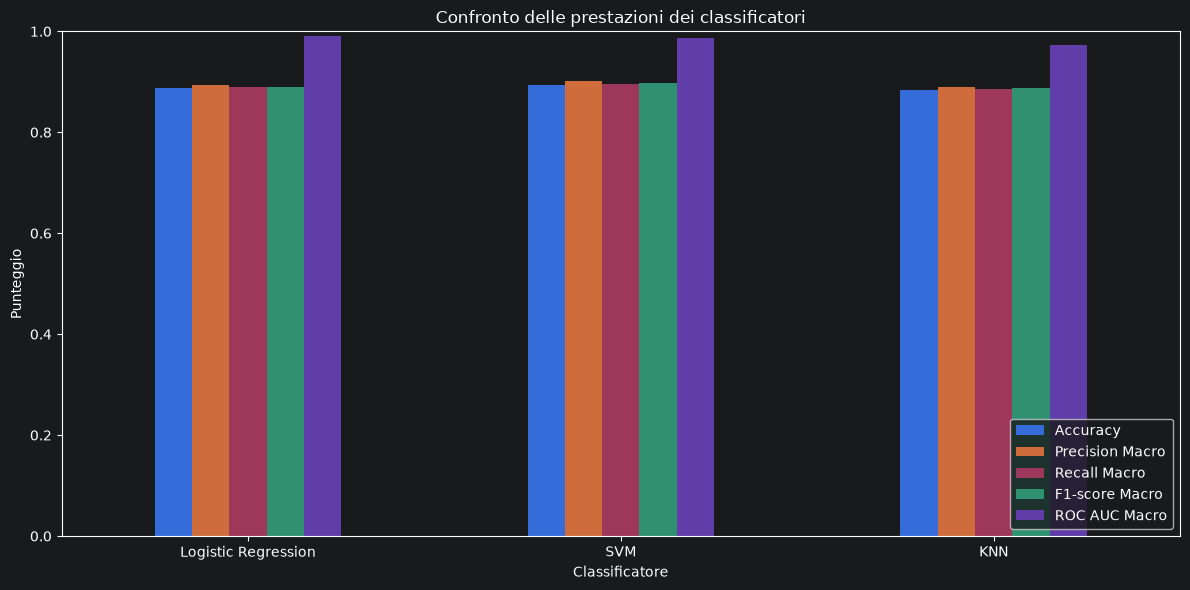

In [9]:
#1. Calcolo probabilit﷿﷿/score
y_prob_lr = log_reg.predict_proba(X_test_pca)
y_score_svm = svm.decision_function(X_test_pca)
y_prob_knn = knn.predict_proba(X_test_pca)

#2. Metriche di valutazione
risultati = {
    "Logistic Regression": {
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Precision Macro": precision_score(
            y_test,
            y_pred_lr,
            average="macro"
        ),
        "Recall Macro": recall_score(
            y_test,
            y_pred_lr,
            average="macro"
        ),
        "F1-score Macro": f1_score(
            y_test,
            y_pred_lr,
            average="macro"
        ),
        "ROC AUC Macro": roc_auc_score(
            y_test_bin,
            y_prob_lr,
            average="macro",
            multi_class="ovr"
        )
    },

    "SVM": {
        "Accuracy": accuracy_score(y_test, y_pred_svm),
        "Precision Macro": precision_score(
            y_test,
            y_pred_svm,
            average="macro"
        ),
        "Recall Macro": recall_score(
            y_test,
            y_pred_svm,
            average="macro"
        ),
        "F1-score Macro": f1_score(
            y_test,
            y_pred_svm,
            average="macro"
        ),
        "ROC AUC Macro": roc_auc_score(
            y_test_bin,
            y_score_svm,
            average="macro",
            multi_class="ovr"
        )
    },

    "KNN": {
        "Accuracy": accuracy_score(y_test, y_pred_knn),
        "Precision Macro": precision_score(
            y_test,
            y_pred_knn,
            average="macro"
        ),
        "Recall Macro": recall_score(
            y_test,
            y_pred_knn,
            average="macro"
        ),
        "F1-score Macro": f1_score(
            y_test,
            y_pred_knn,
            average="macro"
        ),
        "ROC AUC Macro": roc_auc_score(
            y_test_bin,
            y_prob_knn,
            average="macro",
            multi_class="ovr"
        )
    }
}

#3. Confronto tra i classificatori
df_confronto = pd.DataFrame(risultati).T

print(df_confronto)

df_confronto.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Confronto delle prestazioni dei classificatori")
plt.ylabel("Punteggio")
plt.xlabel("Classificatore")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

_DEEP LEARNING_

Classi: ['BARBUNYA' 'BOMBAY' 'CALI' 'DERMASON' 'HOROZ' 'SEKER' 'SIRA']

Dimensione Training DL: (7584, 4)
Dimensione Validation DL: (1896, 4)
Dimensione Test: (4063, 4)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           119 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 807 (3.15 KB)

 Trainable params: 807 (3.15 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
237/237 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5297 - loss: 1.2333 - val_accuracy: 0.7542 - val_loss: 0.6995
Epoch 2/100
237/237 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7872 - loss: 0.6184 - val_accuracy: 0.8470 - val_loss: 0.4321
Epoch 3/100
237/237 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8455 - loss: 0.4513 - val_accuracy: 0.8766 - val_loss: 0.3397
Epoch 4/100
237/237 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8514 - loss: 0.4008 - val_accuracy: 0.8861 - val_loss: 0.3099
Epoch 5/100
237/237 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8646 - loss: 0.3701 - val_accuracy: 0.8845 - val_loss: 0.3004
Epoch 6/100
237/237 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8697 - loss: 0.3469 - val_accuracy: 0.8866 - val_loss: 0.2947
Epoch 7/100
237/237 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8712 - loss: 0.3459 - val_accuracy: 0.8834 - val_loss: 0.2849
Epoch 8/100
237/237 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8730 - loss: 0.3360 - val_accu

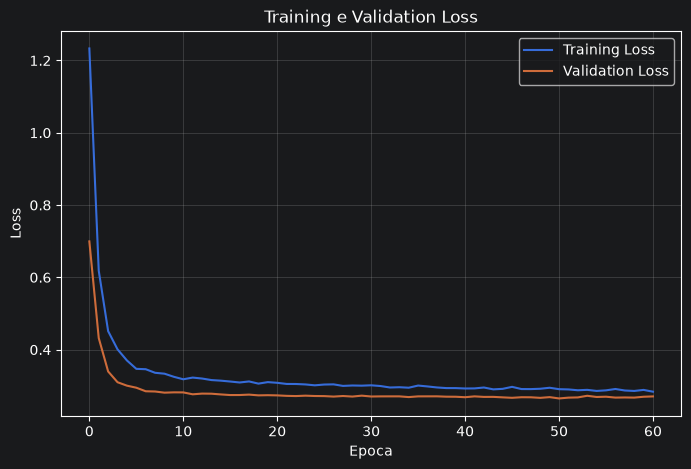

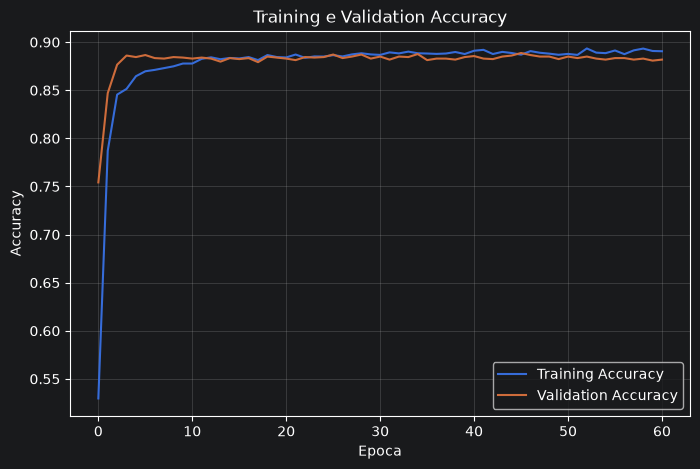

127/127 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step   

REPORT DI CLASSIFICAZIONE - DEEP LEARNING
              precision    recall  f1-score   support

    BARBUNYA       0.89      0.68      0.77       397
      BOMBAY       0.99      1.00      1.00       156
        CALI       0.78      0.92      0.85       489
    DERMASON       0.92      0.89      0.91      1064
       HOROZ       0.96      0.94      0.95       558
       SEKER       0.94      0.94      0.94       608
        SIRA       0.83      0.89      0.86       791

    accuracy                           0.89      4063
   macro avg       0.90      0.89      0.90      4063
weighted avg       0.90      0.89      0.89      4063



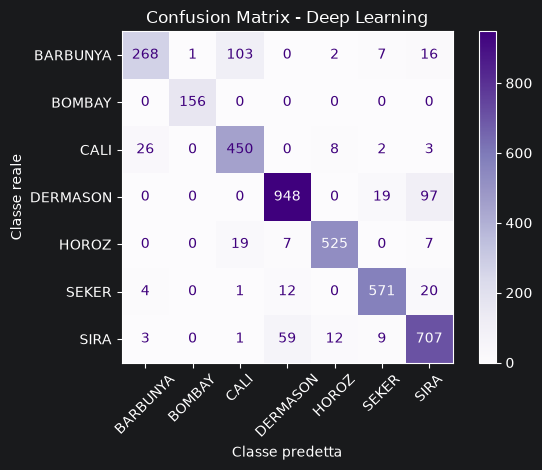


METRICHE DEEP LEARNING
Accuracy: 0.8921978833374354
Precision Macro: 0.9032335456675337
Recall Macro: 0.8942994394720861
F1-score Macro: 0.8956559349504217
ROC AUC Macro: 0.9907260963784712


In [10]:
#1. Codifica numerica del target per la rete neurale
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Classi:", label_encoder.classes_)

# 2. Creazione del Validation Set a partire SOLO dal Training Set
X_train_dl, X_val_dl, y_train_dl, y_val_dl = train_test_split(
    X_train_pca,
    y_train_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_train_encoded
)

print("\nDimensione Training DL:", X_train_dl.shape)
print("Dimensione Validation DL:", X_val_dl.shape)
print("Dimensione Test:", X_test_pca.shape)

#Seed per la riproducibilit﷿﷿
tf.keras.utils.set_random_seed(42)

# 3. Costruzione della rete neurale
model = Sequential([
    Input(shape=(X_train_dl.shape[1],)),

    Dense(32, activation="relu"),
    Dropout(0.2),

    Dense(16, activation="relu"),

    Dense(7, activation="softmax")
])

# 4. Compilazione
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 5. Early Stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# 6. Addestramento
history = model.fit(
    X_train_dl,
    y_train_dl,
    validation_data=(X_val_dl, y_val_dl),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

# 7. Andamento Training / Validation Loss
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoca")
plt.ylabel("Loss")
plt.title("Training e Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 8. Andamento Training / Validation Accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoca")
plt.ylabel("Accuracy")
plt.title("Training e Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 9. Predizione sullo stesso Test Set utilizzato dagli altri classificatori
y_prob_dl = model.predict(X_test_pca)

y_pred_dl_encoded = np.argmax(
    y_prob_dl,
    axis=1
)

# Conversione delle classi numeriche nei nomi originali
y_pred_dl = label_encoder.inverse_transform(
    y_pred_dl_encoded
)

# 10. Classification Report
print("\nREPORT DI CLASSIFICAZIONE - DEEP LEARNING")

print(
    classification_report(
        y_test,
        y_pred_dl,
        zero_division=0
    )
)

# 11. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dl,
    labels=sorted(y.unique()),
    cmap="Purples",
    values_format="d"
)

plt.title("Confusion Matrix - Deep Learning")
plt.xlabel("Classe predetta")
plt.ylabel("Classe reale")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 12. Metriche di valutazione
accuracy_dl = accuracy_score(
    y_test,
    y_pred_dl
)

precision_dl = precision_score(
    y_test,
    y_pred_dl,
    average="macro"
)

recall_dl = recall_score(
    y_test,
    y_pred_dl,
    average="macro"
)

f1_dl = f1_score(
    y_test,
    y_pred_dl,
    average="macro"
)

roc_auc_dl = roc_auc_score(
    y_test_encoded,
    y_prob_dl,
    multi_class="ovr",
    average="macro"
)

print("\nMETRICHE DEEP LEARNING")
print("Accuracy:", accuracy_dl)
print("Precision Macro:", precision_dl)
print("Recall Macro:", recall_dl)
print("F1-score Macro:", f1_dl)
print("ROC AUC Macro:", roc_auc_dl)